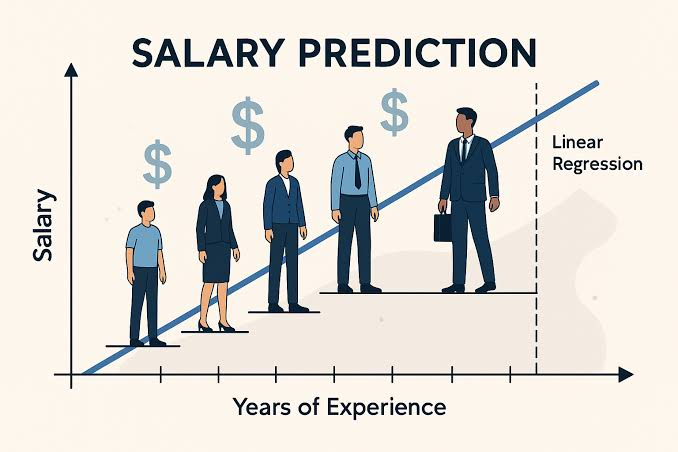

## 1. Business Understanding — Salary Prediction Project

#### 1. Backstory
In today's competitive job market, salary determination is an important part of recruitment and workforce management. Salaries vary depending on factors such as age, education level, years of experience, job title, industry, and location.

Many organizations face difficulties in determining fair and competitive salaries for different job roles. Analyzing historical employee salary data can help identify salary patterns and build a Machine Learning model that estimates salaries based on employee characteristics.

This project uses the job_salary_prediction_dataset.csv dataset to analyze employee-related factors and develop a Salary Prediction model using Machine Learning techniques.

#### 2.💼 Business Problem
Organizations often struggle to determine appropriate salary packages for employees because salary expectations and compensation levels differ across job roles, experience levels, educational qualifications, and other employee attributes.

Manual salary estimation may lead to inconsistent compensation decisions, underpayment or overpayment, and difficulties in creating competitive salary offers.

Therefore, a data-driven solution is needed to predict employee salaries based on relevant features from historical data.

#### 3.🎯 Business Objective
The primary objective of this project is to develop a Machine Learning model that predicts an employee's salary using relevant features available in the dataset.

The specific objectives are:
- Identify the factors that influence employee salaries.
- Analyze relationships between employee characteristics and salary.
- Perform data cleaning and exploratory data analysis (EDA).
- Prepare the dataset for Machine Learning by handling missing values, duplicates, and potential outliers.
- Build and evaluate suitable regression models to predict salaries.
- Identify the model that provides the best prediction performance using appropriate evaluation metrics, such as MAE, MSE, RMSE, and \(R^2\).
- Provide data-driven salary estimates that can support recruitment and compensation planning.
  
#### 4.⚠️Constraints
The project may face the following limitations:

1. Data Quality: Missing values, duplicate records, inconsistent categories, or incorrect salary values may affect model performance.

2. Feature Availability: Prediction accuracy depends on the employee attributes available in the dataset.

3. Outliers: Extremely high or low salary values may influence regression models and require investigation.

4. Model Accuracy: Predicted salaries are estimates and may not exactly match actual salaries.

5. Market Changes: Salary trends can change over time due to inflation, demand for skills, economic conditions, and industry changes.

6. Bias and Fairness: Historical salary data may contain biases, so predictions should be evaluated carefully before being used in employment decisions.

7. Computational Resources: The dataset contains a large number of records, so data processing and model training may require sufficient memory and processing power.

8. Generalization: A model trained on one dataset may not perform equally well for employees from different industries, locations, or job markets.

In [7]:
import pandas as pd

df = pd.read_csv("salary_prediction_dataset.csv")
df.head()

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069


In [8]:
df.shape

(250000, 10)

In [9]:
df.columns

Index(['job_title', 'experience_years', 'education_level', 'skills_count',
       'industry', 'company_size', 'location', 'remote_work', 'certifications',
       'salary'],
      dtype='object')

In [10]:
df.dtypes

job_title           object
experience_years     int64
education_level     object
skills_count         int64
industry            object
company_size        object
location            object
remote_work         object
certifications       int64
salary               int64
dtype: object

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   job_title         250000 non-null  object
 1   experience_years  250000 non-null  int64 
 2   education_level   250000 non-null  object
 3   skills_count      250000 non-null  int64 
 4   industry          250000 non-null  object
 5   company_size      250000 non-null  object
 6   location          250000 non-null  object
 7   remote_work       250000 non-null  object
 8   certifications    250000 non-null  int64 
 9   salary            250000 non-null  int64 
dtypes: int64(4), object(6)
memory usage: 19.1+ MB


In [12]:
df.describe()

,experience_years,skills_count,certifications,salary
count,250000.000000,250000.000000,250000.000000,250000.000000
mean,10.005408,9.997812,2.491928,145718.080524
std,6.060602,5.479288,1.706475,37407.952729
min,0.000000,1.000000,0.000000,31867.000000
25%,5.000000,5.000000,1.000000,119358.000000
50%,10.000000,10.000000,2.000000,143453.000000
75%,15.000000,15.000000,4.000000,169492.000000
max,20.000000,19.000000,5.000000,333046.000000


### Data Preprocessing

In [13]:
df.isnull().sum()

job_title           0
experience_years    0
education_level     0
skills_count        0
industry            0
company_size        0
location            0
remote_work         0
certifications      0
salary              0
dtype: int64

In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df["salary"].min()

31867

In [16]:
df["salary"].max()

333046

<Axes: ylabel='Density'>

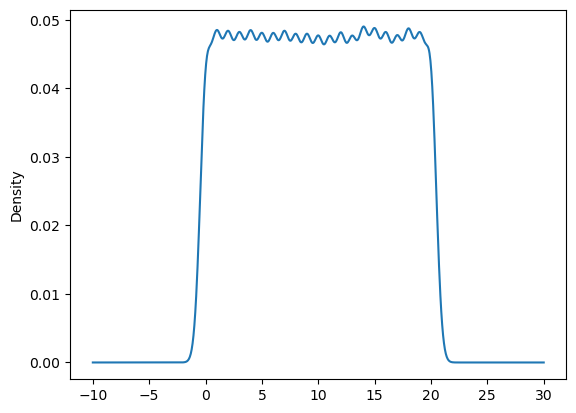

In [17]:
df["experience_years"].plot(kind = "kde")

<Axes: xlabel='education_level'>

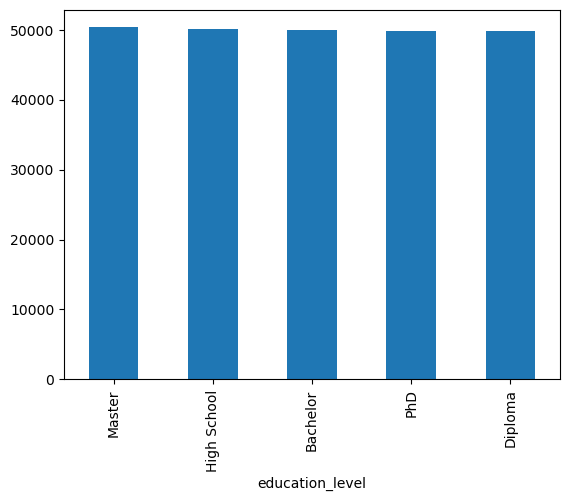

In [18]:
df["education_level"].value_counts().plot(kind = "bar")

<Axes: >

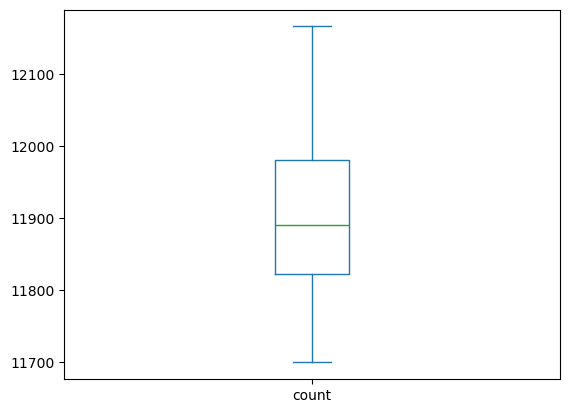

In [19]:
df["experience_years"].value_counts().plot(kind = "box")

<Axes: >

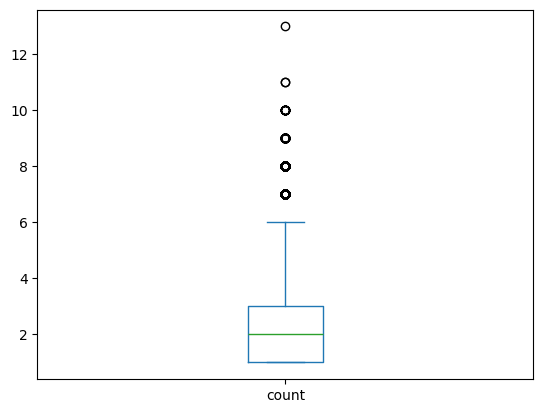

In [20]:
df["salary"].value_counts().plot(kind = "box")

<Axes: xlabel='location'>

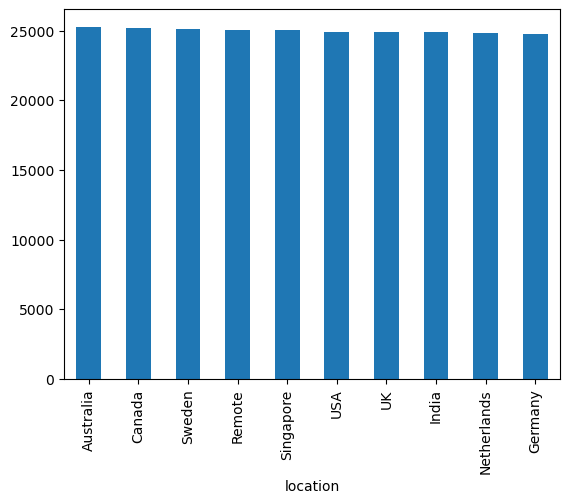

In [21]:
df["location"].value_counts().plot(kind = "bar")

In [22]:
df["experience_years"].unique()

array([10,  5, 18, 19, 15,  0,  6,  4,  1,  8,  3, 14, 11,  9, 17, 12, 13,
        2,  7, 20, 16])

In [23]:
df["education_level"].unique()

array(['Bachelor', 'PhD', 'High School', 'Diploma', 'Master'],
      dtype=object)

In [24]:
df["job_title"].unique()

array(['AI Engineer', 'Data Analyst', 'Frontend Developer',
       'Business Analyst', 'Product Manager', 'Backend Developer',
       'Machine Learning Engineer', 'DevOps Engineer',
       'Software Engineer', 'Cybersecurity Analyst', 'Data Scientist',
       'Cloud Engineer'], dtype=object)

In [25]:
df["location"].unique()

array(['India', 'Australia', 'Singapore', 'Canada', 'Sweden', 'USA',
       'Netherlands', 'Remote', 'Germany', 'UK'], dtype=object)

In [26]:
df["industry"].unique()

array(['Healthcare', 'Telecom', 'Media', 'Retail', 'Manufacturing',
       'Education', 'Finance', 'Technology', 'Consulting', 'Government'],
      dtype=object)

In [27]:
# Encoding 
# Manually Encoded

# df["education_level"] = df["education_level"].map({"High School":1, "Diploma":2, "Bachelor":3, "Master":4, "PhD":5})
# df["education_level"]

In [28]:
# using label encoding

from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
job_encoder = LabelEncoder()
location_encoder = LabelEncoder()
industry_encoder = LabelEncoder()
education_encoder = LabelEncoder()

df["job_title"] = job_encoder.fit_transform(df["job_title"]) 
df["location"] = location_encoder.fit_transform(df["location"])
df["industry"] = industry_encoder.fit_transform(df["industry"])
df["education_level"] = education_encoder.fit_transform(df["education_level"])

# fit_transform() is used to convert categorical to numeric 

In [29]:
df.dtypes

job_title            int64
experience_years     int64
education_level      int64
skills_count         int64
industry             int64
company_size        object
location             int64
remote_work         object
certifications       int64
salary               int64
dtype: object

## Model Building

In [30]:
df.head()

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,0,10,0,2,4,Medium,3,Hybrid,2,109413
1,5,5,0,17,9,Small,0,No,0,93764
2,8,18,4,4,6,Medium,6,No,1,148123
3,2,19,4,13,7,Medium,1,Yes,0,189123
4,10,15,0,7,5,Large,7,Yes,0,165069


In [31]:
# Feature Selection
# Input Features
X = df[["job_title","experience_years","education_level","industry","location"]]

In [32]:
X

,job_title,experience_years,education_level,industry,location
0,0,10,0,4,3
1,5,5,0,9,0
2,8,18,4,6,6
3,2,19,4,7,1
4,10,15,0,5,7
...,...,...,...,...,...
249995,11,17,4,9,3
249996,8,20,4,9,5
249997,2,1,0,7,3
249998,6,0,2,0,7


In [33]:
# Output / Target 
y = df["salary"]
y

0         109413
1          93764
2         148123
3         189123
4         165069
           ...  
249995    127791
249996    154593
249997     75988
249998     90467
249999    133084
Name: salary, Length: 250000, dtype: int64

In [34]:
from sklearn.model_selection import train_test_split

In [35]:
X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 42
)

In [36]:
X_train.head()

,job_title,experience_years,education_level,industry,location
75381,9,4,1,8,3
65569,1,1,4,0,7
163473,1,16,2,5,1
90518,5,4,2,2,8
138866,1,7,1,7,2


In [37]:
y_train.head()

75381      97647
65569     144887
163473    147645
90518      92191
138866    113442
Name: salary, dtype: int64

In [38]:
print("training input shape:",X_train.shape)
print("training output shape:",y_train.shape)
print()
print("testing input shape:",X_test.shape)
print("testing output shape:",y_test.shape)

training input shape: (200000, 5)
training output shape: (200000,)

testing input shape: (50000, 5)
testing output shape: (50000,)


In [39]:
# Linear Regression 
# Linear Regression is applied when the Target/Output column is numerical 

from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

In [40]:
lr = LinearRegression()
lr

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [41]:
print(df.isnull().sum())

job_title           0
experience_years    0
education_level     0
skills_count        0
industry            0
company_size        0
location            0
remote_work         0
certifications      0
salary              0
dtype: int64


In [42]:
lr.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [43]:
# Prediction --- By giving X_test data we predict the result
y_pred = lr.predict(X_test)
y_pred

array([127673.10859491, 140163.23628158, 130525.87279876, ...,
       156324.99736977, 171092.42709956, 126877.45229119], shape=(50000,))

In [44]:
# Using Regression Metrics now we check how well model learned from the given data 

root_mean_squared_error(y_test,y_pred)

31801.390228501637

In [45]:
# Using KNN

from sklearn.neighbors import KNeighborsRegressor
knn = KNeighborsRegressor()
knn.fit(X_train,y_train)
y_pred = knn.predict(X_test)
y_pred

array([188014.2, 102122.2,  91230.2, ..., 146877. , 171484.4, 136158.8],
      shape=(50000,))

In [46]:
root_mean_squared_error(y_test,y_pred)

20333.977449627724

In [47]:
# Using Decision Tree Regression

from sklearn.tree import DecisionTreeRegressor
dt = DecisionTreeRegressor()
dt.fit(X_train,y_train)
y_pred = dt.predict(X_test)
y_pred

array([192951.33333333,  85387.        ,  85639.66666667, ...,
       149429.33333333, 139236.5       , 117447.        ], shape=(50000,))

In [48]:
root_mean_squared_error(y_test,y_pred)

22578.804125249597

## Model Deployment

In [49]:
import warnings 
warnings.filterwarnings('ignore')

In [50]:
import pickle

In [51]:
with open(r"salary_model.pkl","wb") as file:
    pickle.dump(knn,file)

In [52]:
with open(r"salary_model.pkl","rb") as file:
    model = pickle.load(file)

model

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [53]:
# def prediction(job,education,experience,industry,location):
#     return model.predict([[job,education,experience,industry,location]])[0]

In [54]:
def prediction(job, education, experience, industry, location):

    # Convert text inputs into numbers
    job = job_encoder.transform([job])[0]  # [0] It gives single number instead of an array like 85000.20 instead of [85000.20]
    industry = industry_encoder.transform([industry])[0]
    location = location_encoder.transform([location])[0]
    education = education_encoder.transform([education])[0]
    
    # Predict salary
    result = model.predict([[job,experience,education,industry,location]])[0]

    return f"Predicted Salary: ₹{result:,.2f}"

### User Interface

In [55]:
# Interface

import gradio as gr

In [56]:
# iface = gr.Interface(fn = prediction,
#                      title = "Employee Salary Prediction",
#                      outputs = gr.Textbox(label = "Predicted Salary"),
#                      inputs = [ 
#                          gr.Number(label = "Job"),
#                          gr.Number(label = "Education"),
#                          gr.Number(label = "Experience Years"),
#                          gr.Number(label = "Industry Type"),
#                          gr.Number(label = "Location"),
#                      ]
#                     )

In [64]:
iface = gr.Interface(fn = prediction,
                     title = "Employee Salary Prediction",
                     outputs = gr.Textbox(label = "Predicted Salary"),
                     inputs = [ 
                         gr.Textbox(label = "Job"),
                         gr.Textbox(label = "Education"),
                         gr.Number(label = "Experience Years"),
                         gr.Textbox(label = "Industry Type"),
                         gr.Textbox(label = "Location"),
                     ]
                    )

In [65]:
# Launching Of Application

iface.launch(share = True)

* Running on local URL:  http://127.0.0.1:7862

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


2026/10/28 17:48:45 [W] [service.go:132] login to server failed: dial tcp 44.237.78.176:7000: i/o timeout
